# Keyword and Entity Extraction using IBM WatsonX.ai - Parquet Data Analysis

This notebook demonstrates how to extract keywords and entities from the IBM test data (parquet format) using IBM WatsonX.ai foundation models, followed by comprehensive statistical analysis.

## Table of Contents
1. [Setup and Installation](#setup)
2. [Load Dataset from Parquet](#load-data)
3. [Initialize WatsonX.ai Client](#init-watsonx)
4. [Keyword Extraction](#keyword-extraction)
5. [Entity Extraction](#entity-extraction)
6. [Batch Processing](#batch-processing)
7. [Save Results](#save-results)
8. [Statistical Analysis](#statistical-analysis)

## 1. Setup and Installation <a name="setup"></a>

First, install the required packages.

### Import Required Libraries

In [1]:
import os
import pandas as pd
import numpy as np
import json
import re
from typing import List, Dict, Optional
from collections import Counter
from dotenv import load_dotenv
import matplotlib.pyplot as plt
import seaborn as sns

# IBM WatsonX.ai imports
from ibm_watsonx_ai.credentials import Credentials
from ibm_watsonx_ai import APIClient
from ibm_watsonx_ai.foundation_models import ModelInference

# Set plotting style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')

print("✓ All libraries imported successfully")

✓ All libraries imported successfully


### Configure Credentials

Set up your IBM Cloud credentials. Refer to `IBM_CREDENTIALS_SETUP.md` for detailed instructions.

In [2]:
# Load environment variables
load_dotenv()

WATSONX_API_KEY = os.getenv('WATSONX_API_KEY', 'your-api-key-here')
WATSONX_PROJECT_ID = os.getenv('WATSONX_PROJECT_ID', 'your-project-id-here')
WATSONX_URL = os.getenv('WATSONX_URL', 'https://us-south.ml.cloud.ibm.com')

if WATSONX_API_KEY == 'your-api-key-here':
    print("⚠️  Warning: Please set your WatsonX.ai credentials")
else:
    print("✓ Credentials loaded successfully")

✓ Credentials loaded successfully


## 2. Load Dataset from Parquet <a name="load-data"></a>

In [3]:
PARQUET_PATH = "/Users/abhilashamangal/Documents/2026/Github/ShareThis-Predictive-Multilabel-Classification/data/ibm_test_data.parquet"

df = pd.read_parquet(PARQUET_PATH)
print(f"✓ Dataset loaded: {df.shape}")
print(f"  Columns: {list(df.columns)}")
display(df.head(3))
df.info()

✓ Dataset loaded: (17275, 2)
  Columns: ['text_id', 'text']


,text_id,text
0,1138,Embark on a seamless journey with our tours fr...
1,1181,We’re living in hotels full-time at the moment...
2,1274,Scary | Yo Gabba Gabba Wiki | Fandom \n Yo Gab...


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17275 entries, 0 to 17274
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   text_id  17275 non-null  object
 1   text     17275 non-null  object
dtypes: object(2)
memory usage: 270.1+ KB


In [4]:
# Prepare sample
SAMPLE_SIZE = 10
df_sample = df.head(SAMPLE_SIZE).copy()
print(f"✓ Prepared {len(df_sample)} samples")

✓ Prepared 10 samples


## 3. Initialize WatsonX.ai Client <a name="init-watsonx"></a>

In [5]:
credentials = Credentials(url=WATSONX_URL, api_key=WATSONX_API_KEY)
MODEL_ID = "mistralai/mistral-small-3-1-24b-instruct-2503"
parameters = {
    "decoding_method": "greedy",
    "temperature": 0.1,
    "max_new_tokens": 2000,
    "min_new_tokens": 10,
    "repetition_penalty": 1.0
}

model = ModelInference(
    model_id=MODEL_ID,
    params=parameters,
    credentials=credentials,
    project_id=WATSONX_PROJECT_ID
)
print(f"✓ Model initialized: {MODEL_ID}")

✓ Model initialized: mistralai/mistral-small-3-1-24b-instruct-2503


## 4. Keyword Extraction <a name="keyword-extraction"></a>

In [6]:
import json
from typing import Dict, Any
def extract_keywords(text: str, url: str = "", max_keywords: int = 10) -> Dict[str, Any]:
   
    prompt = f"""[INST]

    You are an expert NLP information extraction system.

    TASK:
    Analyze the given text and extract the most important information into three distinct categories:

    1. keywords → Important single-word terms only
    2. phrases → Important multi-word key phrases only
    3. concepts → High-level themes, categories, or core ideas discussed in the text

    PRE-REQUIRED THEME UNDERSTANDING:
    Before extraction, first understand:
    - the main subject of the text
    - the domain it belongs to
    - the primary discussion theme
    - the important technical context

    Then perform extraction based on semantic importance, not just word frequency.

    STRICT EXTRACTION RULES:
    - Extract up to {max_keywords} total items across all categories combined
    - keywords must contain only single meaningful words
    - phrases must contain only multi-word expressions
    - concepts must represent broader ideas, categories, or major themes
    - Do NOT duplicate the same term across categories
    - Do NOT repeat the same idea in slightly different forms
    - Do NOT include sub-phrases if a stronger full phrase exists

    Example:
    Prefer "Natural Language Processing" over "Language Processing"

    - Prefer complete and meaningful expressions
    - Preserve exact technical names where relevant
    - Exclude generic words, filler words, weak terms, and low-value tokens
    - Prioritize domain-specific and contextually important information
    - Keep output concise, clean, and highly relevant

    STRICT OUTPUT RULES:
    - Return ONLY valid JSON
    - Do NOT include markdown
    - Do NOT include explanations
    - Do NOT include notes
    - Do NOT include additional text before or after JSON
    - If unsure, return empty arrays instead of explanations

    RETURN EXACTLY IN THIS JSON STRUCTURE:

    {{
      "theme": "main topic of the text",
      "keywords": [
        "keyword1",
        "keyword2"
      ],
      "phrases": [
        "key phrase 1",
        "key phrase 2"
      ],
      "concepts": [
        "core concept 1",
        "core concept 2"
      ]
    }}

    TEXT:
    {text}

    [/INST]"""

    try:
        print(f"Prompt:\n{prompt}")

        result = model.generate_text(
            prompt=prompt,
            guardrails=False
        )

        result = result.strip()

        print("Raw Model Output:")
        print(result)

        # Parse only valid JSON object
        if result.startswith("{") and result.endswith("}"):
            parsed_result = json.loads(result)

            # Safety fallback for missing keys
            return {
                "theme": parsed_result.get("theme", ""),
                "keywords": parsed_result.get("keywords", []),
                "phrases": parsed_result.get("phrases", []),
                "concepts": parsed_result.get("concepts", [])
            }

        print("Invalid JSON response received")
        return {
            "theme": "",
            "keywords": [],
            "phrases": [],
            "concepts": []
        }

    except Exception as e:
        print(f"Keyword extraction error: {str(e)}")

        return {
            "theme": "",
            "keywords": [],
            "phrases": [],
            "concepts": []
        }


print("✓ Keyword extraction function defined")

✓ Keyword extraction function defined


## 5. Entity Extraction <a name="entity-extraction"></a>

In [7]:
import json
from typing import Dict, List


def extract_entities(text: str, url: str = "") -> Dict[str, List[str]]:
    print("Entity extraction started -----")

    prompt = f"""[INST]

You are an expert Named Entity Recognition (NER) and entity extraction system.

TASK:
Analyze the given text and extract all important named entities, then categorize them into the appropriate entity types.

ENTITY CATEGORIES:
- PERSON → Individual people, authors, researchers, founders, public figures
- ORGANIZATION → Companies, institutions, universities, agencies, teams, brands
- LOCATION → Countries, cities, states, regions, landmarks, places
- DATE → Specific dates, years, months, time references
- EVENT → Conferences, wars, launches, festivals, historical events, major occurrences
- PRODUCT → Software, tools, applications, devices, frameworks, commercial products
- OTHER → Important named entities that do not clearly fit the above categories

PRE-ANALYSIS:
Before extraction, first understand:
- the main subject of the text
- the domain and context
- whether the term is truly a named entity or just a generic noun

Then perform entity extraction based on contextual meaning, not only capitalization.

STRICT EXTRACTION RULES:
- Extract only meaningful named entities
- Do NOT include generic words or common nouns
- Do NOT include duplicate entities
- Do NOT repeat the same entity in multiple categories
- Preserve exact entity names as written when possible
- Prefer full entity names over partial names

Example:
Prefer "Stanford University" over "Stanford"

- Ignore weak references unless they are contextually important
- Keep output clean, precise, and domain-relevant

STRICT OUTPUT RULES:
- Return ONLY valid JSON
- Do NOT include markdown
- Do NOT include explanations
- Do NOT include notes
- Do NOT include additional text before or after JSON
- If no entities exist for a category, return an empty array
- If unsure, return empty arrays instead of explanations

RETURN EXACTLY IN THIS JSON STRUCTURE:

{{
  "PERSON": [],
  "ORGANIZATION": [],
  "LOCATION": [],
  "DATE": [],
  "EVENT": [],
  "PRODUCT": [],
  "OTHER": []
}}

TEXT:
{text}

[/INST]"""

    try:
        result = model.generate_text(
            prompt=prompt,
            guardrails=False
        )

        result = result.strip()

        # Extract valid JSON block safely
        start_idx = result.find("{")
        end_idx = result.rfind("}")

        if start_idx != -1 and end_idx != -1:
            json_text = result[start_idx:end_idx + 1]

            parsed_result = json.loads(json_text)

            # Ensure all required keys exist
            return {
                "PERSON": parsed_result.get("PERSON", []),
                "ORGANIZATION": parsed_result.get("ORGANIZATION", []),
                "LOCATION": parsed_result.get("LOCATION", []),
                "DATE": parsed_result.get("DATE", []),
                "EVENT": parsed_result.get("EVENT", []),
                "PRODUCT": parsed_result.get("PRODUCT", []),
                "OTHER": parsed_result.get("OTHER", [])
            }

        print("Invalid JSON response received")

        return {
            "PERSON": [],
            "ORGANIZATION": [],
            "LOCATION": [],
            "DATE": [],
            "EVENT": [],
            "PRODUCT": [],
            "OTHER": []
        }

    except Exception as e:
        print(f"Entity extraction error: {str(e)}")

        return {
            "PERSON": [],
            "ORGANIZATION": [],
            "LOCATION": [],
            "DATE": [],
            "EVENT": [],
            "PRODUCT": [],
            "OTHER": []
        }


print("✓ Entity extraction function defined")

✓ Entity extraction function defined


## 6. Batch Processing <a name="batch-processing"></a>

In [8]:
import pandas as pd
from typing import Dict, Any
def process_batch(df: pd.DataFrame, max_keywords: int = 50) -> pd.DataFrame:
    """
    Process dataframe and add:
    - theme
    - keywords
    - phrases
    - concepts
    - PERSON
    - ORGANIZATION
    - LOCATION
    - DATE
    - EVENT
    - PRODUCT
    - OTHER
    """
    results = []

    # Detect columns
    text_col = "text" if "text" in df.columns else df.columns[0]
    url_col = "url" if "url" in df.columns else None

    print("\nStarting batch processing...")
    print("=" * 70)

    # Process full dataframe (remove [0:1] limitation)
    for idx, row in df.iterrows():
        url = row[url_col] if url_col else ""
        text = str(row[text_col])

        print(f"\nProcessing {idx + 1}/{len(df)}...")

        try:
            # Extract keywords / phrases / concepts / theme
            keyword_data = extract_keywords(
                text=text,
                url=url,
                max_keywords=max_keywords
            )

            print("Keyword Extraction Result:")
            print(keyword_data)

            # Extract entities
            entity_data = extract_entities(
                text=text,
                url=url
            )

            print("Entity Extraction Result:")
            #print(entity_data)

            total_entities = sum(
                len(v) for v in entity_data.values()
            )

            print(
                f"✓ Theme extracted | "
                f"Keywords: {len(keyword_data.get('keywords', []))} | "
                f"Phrases: {len(keyword_data.get('phrases', []))} | "
                f"Concepts: {len(keyword_data.get('concepts', []))} | "
                f"Entities: {total_entities}"
            )

            results.append({
                "theme": keyword_data.get("theme", ""),
                "keywords": keyword_data.get("keywords", []),
                "phrases": keyword_data.get("phrases", []),
                "concepts": keyword_data.get("concepts", []),

                "PERSON": entity_data.get("PERSON", []),
                "ORGANIZATION": entity_data.get("ORGANIZATION", []),
                "LOCATION": entity_data.get("LOCATION", []),
                "DATE": entity_data.get("DATE", []),
                "EVENT": entity_data.get("EVENT", []),
                "PRODUCT": entity_data.get("PRODUCT", []),
                "OTHER": entity_data.get("OTHER", [])
            })

        except Exception as e:
            print(f"❌ Error processing row {idx}: {str(e)}")

            results.append({
                "theme": "",
                "keywords": [],
                "phrases": [],
                "concepts": [],

                "PERSON": [],
                "ORGANIZATION": [],
                "LOCATION": [],
                "DATE": [],
                "EVENT": [],
                "PRODUCT": [],
                "OTHER": []
            })

    # Add all extracted values back into dataframe
    df["theme"] = [r["theme"] for r in results]
    df["keywords"] = [r["keywords"] for r in results]
    df["phrases"] = [r["phrases"] for r in results]
    df["concepts"] = [r["concepts"] for r in results]

    df["PERSON"] = [r["PERSON"] for r in results]
    df["ORGANIZATION"] = [r["ORGANIZATION"] for r in results]
    df["LOCATION"] = [r["LOCATION"] for r in results]
    df["DATE"] = [r["DATE"] for r in results]
    df["EVENT"] = [r["EVENT"] for r in results]
    df["PRODUCT"] = [r["PRODUCT"] for r in results]
    df["OTHER"] = [r["OTHER"] for r in results]

    print("\n✓ Batch processing completed successfully")

    return df


print("✓ Batch processing function defined")

✓ Batch processing function defined


In [9]:
print(f"Starting batch processing...\n" + "="*70)
df_results = process_batch(df_sample, max_keywords=10)
print("\n" + "="*70 + "\n✓ Complete!")

Starting batch processing...

Starting batch processing...

Processing 1/10...
Prompt:
[INST]

    You are an expert NLP information extraction system.

    TASK:
    Analyze the given text and extract the most important information into three distinct categories:

    1. keywords → Important single-word terms only
    2. phrases → Important multi-word key phrases only
    3. concepts → High-level themes, categories, or core ideas discussed in the text

    PRE-REQUIRED THEME UNDERSTANDING:
    Before extraction, first understand:
    - the main subject of the text
    - the domain it belongs to
    - the primary discussion theme
    - the important technical context

    Then perform extraction based on semantic importance, not just word frequency.

    STRICT EXTRACTION RULES:
    - Extract up to 10 total items across all categories combined
    - keywords must contain only single meaningful words
    - phrases must contain only multi-word expressions
    - concepts must represent br

In [10]:
# View sample results
for idx in range(min(3, len(df_results))):
    row = df_results.iloc[idx]
    print(f"\n{'='*70}\nSample {idx+1}\n{'='*70}")
    print(f"Keywords ({len(row['keywords'])}): {row['keywords']}")
    print(f"Entities: {row['OTHER']}")


Sample 1
Keywords (5): ['Shanghai', 'Tours', 'Adventures', 'Transportation', 'Destinations']
Entities: ['tours', 'train tickets', 'flights', 'short trips', 'excursions', 'transportation hub', 'tourist cities', 'local resources', 'cultural experiences', 'scenic landscapes', 'high-speed train', 'domestic flight', 'guided services', 'tourist destinations', 'customizable services', 'itinerary']

Sample 2
Keywords (4): ['Thompson', 'Dallas', 'Hyatt', 'points']
Entities: ['Globalist suite upgrade award']

Sample 3
Keywords (3): ['Characters', 'Episodes', 'Guests']
Entities: ['DJ Lance', 'Muno', 'Foofa', 'Brobee', 'Toodee', 'Plex', 'Gabbapedia']


## 7. Save Results <a name="save-results"></a>

In [11]:
output_json = "../data/extraction_results_parquet.json"
df_results.to_json(output_json, orient='records', indent=2)

print(f"✓ Results saved:\n  JSON: {output_json}")

✓ Results saved:
  JSON: ../data/extraction_results_parquet.json


## 8. Statistical Analysis <a name="statistical-analysis"></a>

Comprehensive analysis of extracted keywords and entities.

### 8.1 Basic Statistics

In [12]:
# Check if dataframe has separate columns or combined columns
has_separate_cols = 'keywords' in df_results.columns and 'phrases' in df_results.columns
entity_cols = ['PERSON', 'ORGANIZATION', 'LOCATION', 'DATE', 'EVENT', 'PRODUCT', 'OTHER']

if has_separate_cols:
    # Count from separate columns
    total_keywords = sum(len(kw) if isinstance(kw, list) else 0 for kw in df_results['keywords'])
    total_phrases = sum(len(p) if isinstance(p, list) else 0 for p in df_results['phrases'])
    total_concepts = sum(len(c) if isinstance(c, list) else 0 for c in df_results['concepts'])
    total_all = total_keywords + total_phrases + total_concepts
    
    # Count entities from separate columns
    total_entities = sum(sum(len(df_results[col].iloc[i]) if isinstance(df_results[col].iloc[i], list) else 0 
                             for col in entity_cols if col in df_results.columns) 
                        for i in range(len(df_results)))
else:
    # Fallback to dictionary format
    def count_keyword_items(kw_dict):
        if isinstance(kw_dict, dict):
            total = 0
            if 'keywords' in kw_dict:
                total += len(kw_dict['keywords'])
            if 'phrases' in kw_dict:
                total += len(kw_dict['phrases'])
            if 'concepts' in kw_dict:
                total += len(kw_dict['concepts'])
            return total
        return len(kw_dict) if isinstance(kw_dict, list) else 0
    
    total_all = sum(count_keyword_items(kw) for kw in df_results['keywords'])
    total_entities = sum(sum(len(v) for v in ent.values()) if isinstance(ent, dict) else 0 for ent in df_results['entities'])

avg_all = total_all / len(df_results)
avg_entities = total_entities / len(df_results)

print("="*80)
print("EXTRACTION SUMMARY")
print("="*80)
print(f"\nSamples processed: {len(df_results)}")

if has_separate_cols:
    print(f"\nKeywords: {total_keywords}")
    print(f"Phrases: {total_phrases}")
    print(f"Concepts: {total_concepts}")
    print(f"Total (Keywords + Phrases + Concepts): {total_all}")
    print(f"Average per sample: {avg_all:.2f}")
else:
    print(f"\nTotal (Keywords + Phrases + Concepts): {total_all}")
    print(f"Average per sample: {avg_all:.2f}")

print(f"\nEntities:")
print(f"  Total: {total_entities}")
print(f"  Average: {avg_entities:.2f}")

if has_separate_cols:
    print(f"\nEntity breakdown:")
    for col in entity_cols:
        if col in df_results.columns:
            count = sum(len(df_results[col].iloc[i]) if isinstance(df_results[col].iloc[i], list) else 0 
                       for i in range(len(df_results)))
            print(f"  {col}: {count}")

print("\n" + "="*80)

EXTRACTION SUMMARY

Samples processed: 10

Keywords: 47
Phrases: 29
Concepts: 20
Total (Keywords + Phrases + Concepts): 96
Average per sample: 9.60

Entities:
  Total: 206
  Average: 20.60

Entity breakdown:
  PERSON: 51
  ORGANIZATION: 25
  LOCATION: 29
  DATE: 19
  EVENT: 4
  PRODUCT: 4
  OTHER: 74



### 8.2 Keyword Distribution

KEYWORD DISTRIBUTION (including phrases and concepts)
Mean: 9.60
Median: 9.50
Std Dev: 1.85


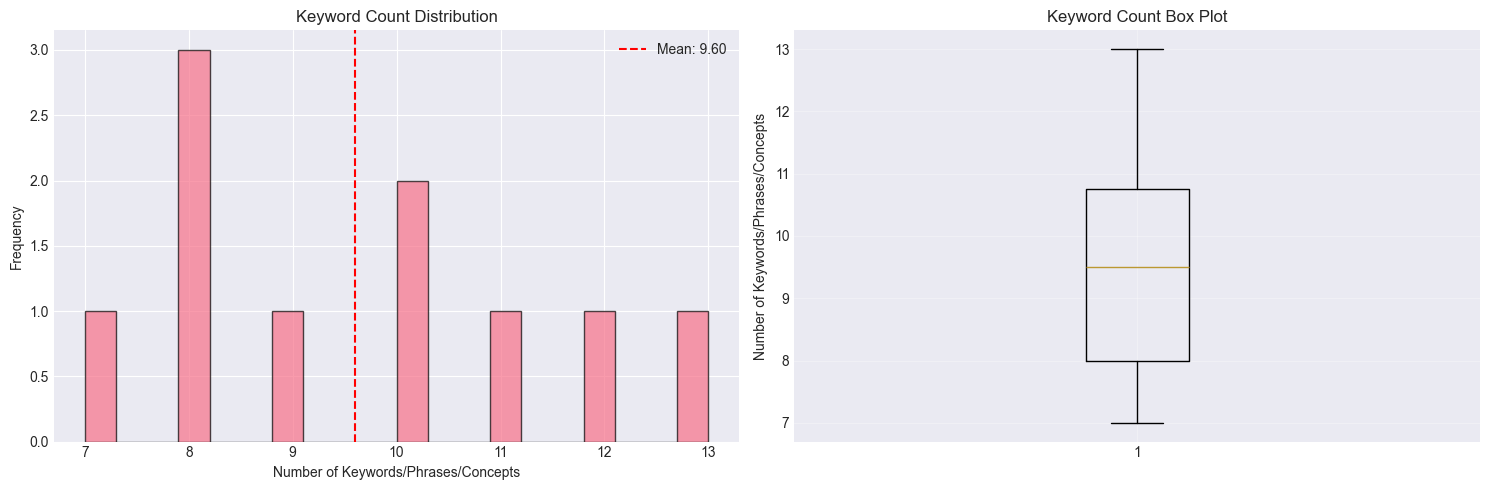

In [13]:
if has_separate_cols:
    keyword_counts = [len(df_results['keywords'].iloc[i]) + len(df_results['phrases'].iloc[i]) + len(df_results['concepts'].iloc[i]) 
                     if isinstance(df_results['keywords'].iloc[i], list) else 0 
                     for i in range(len(df_results))]
else:
    keyword_counts = [count_keyword_items(kw) for kw in df_results['keywords']]

print("KEYWORD DISTRIBUTION (including phrases and concepts)")
print(f"Mean: {np.mean(keyword_counts):.2f}")
print(f"Median: {np.median(keyword_counts):.2f}")
print(f"Std Dev: {np.std(keyword_counts):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].hist(keyword_counts, bins=20, edgecolor='black', alpha=0.7)
axes[0].set_xlabel('Number of Keywords/Phrases/Concepts')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Keyword Count Distribution')
axes[0].axvline(np.mean(keyword_counts), color='red', linestyle='--', label=f'Mean: {np.mean(keyword_counts):.2f}')
axes[0].legend()

axes[1].boxplot(keyword_counts)
axes[1].set_ylabel('Number of Keywords/Phrases/Concepts')
axes[1].set_title('Keyword Count Box Plot')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 8.3 Most Common Keywords

TOP 20 MOST COMMON KEYWORDS/PHRASES/CONCEPTS

Total unique items: 94

   1. characters                               -   2 occurrences
   2. episodes                                 -   2 occurrences
   3. shanghai                                 -   1 occurrences
   4. tours                                    -   1 occurrences
   5. adventures                               -   1 occurrences
   6. transportation                           -   1 occurrences
   7. destinations                             -   1 occurrences
   8. high-speed train                         -   1 occurrences
   9. domestic flight                          -   1 occurrences
  10. guided services                          -   1 occurrences
  11. travel convenience                       -   1 occurrences
  12. cultural experiences                     -   1 occurrences
  13. thompson                                 -   1 occurrences
  14. dallas                                   -   1 occurrences
  15. hyatt         

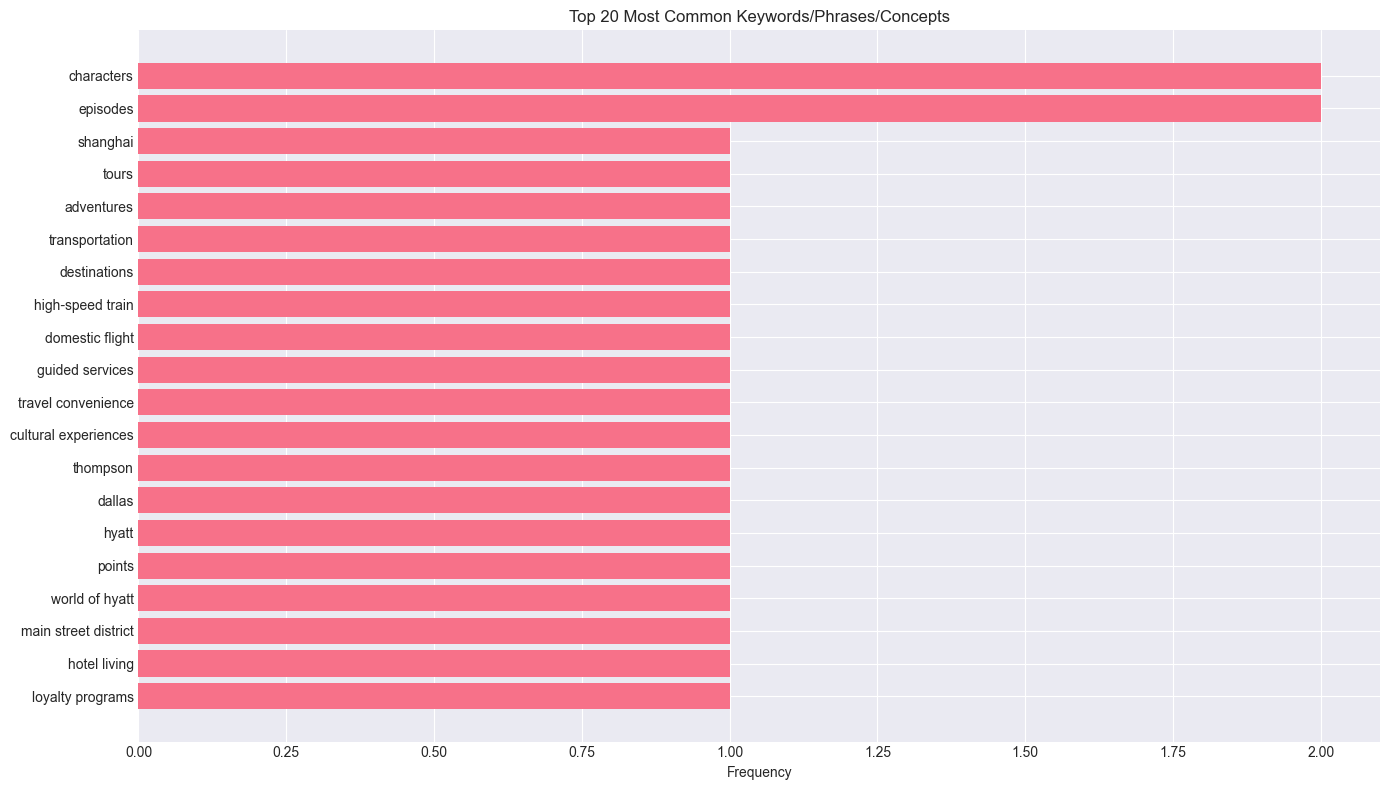

In [14]:
# Extract all keywords, phrases, and concepts
all_keywords = []

if has_separate_cols:
    # Extract from separate columns
    for i in range(len(df_results)):
        if isinstance(df_results['keywords'].iloc[i], list):
            all_keywords.extend([kw.lower() for kw in df_results['keywords'].iloc[i]])
        if isinstance(df_results['phrases'].iloc[i], list):
            all_keywords.extend([p.lower() for p in df_results['phrases'].iloc[i]])
        if isinstance(df_results['concepts'].iloc[i], list):
            all_keywords.extend([c.lower() for c in df_results['concepts'].iloc[i]])
else:
    # Extract from dictionary format
    for kw_dict in df_results['keywords']:
        if isinstance(kw_dict, dict):
            if 'keywords' in kw_dict:
                all_keywords.extend([kw.lower() for kw in kw_dict['keywords']])
            if 'phrases' in kw_dict:
                all_keywords.extend([kw.lower() for kw in kw_dict['phrases']])
            if 'concepts' in kw_dict:
                all_keywords.extend([kw.lower() for kw in kw_dict['concepts']])
        elif isinstance(kw_dict, list):
            all_keywords.extend([kw.lower() for kw in kw_dict])

keyword_counter = Counter(all_keywords)
top_keywords = keyword_counter.most_common(20)

print("="*80)
print("TOP 20 MOST COMMON KEYWORDS/PHRASES/CONCEPTS")
print("="*80)
print(f"\nTotal unique items: {len(keyword_counter)}\n")
for i, (kw, count) in enumerate(top_keywords, 1):
    print(f"  {i:2d}. {kw:40s} - {count:3d} occurrences")

if top_keywords:
    keywords, counts = zip(*top_keywords)
    plt.figure(figsize=(14, 8))
    plt.barh(range(len(keywords)), counts)
    plt.yticks(range(len(keywords)), keywords)
    plt.xlabel('Frequency')
    plt.title('Top 20 Most Common Keywords/Phrases/Concepts')
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

### 8.4 Entity Type Distribution

ENTITY TYPE DISTRIBUTION

Total entity types: 7

  OTHER               :   74 entities
  PERSON              :   51 entities
  LOCATION            :   29 entities
  ORGANIZATION        :   25 entities
  DATE                :   19 entities
  EVENT               :    4 entities
  PRODUCT             :    4 entities


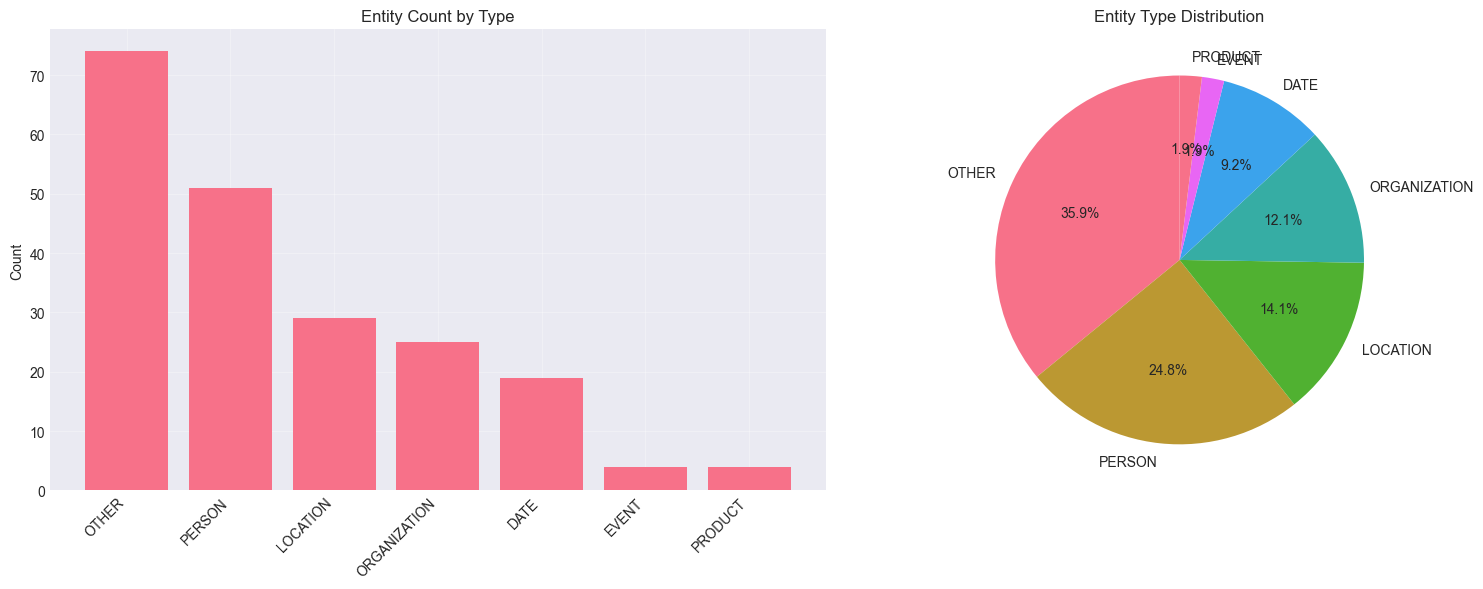

In [15]:
entity_type_counts = Counter()

if has_separate_cols:
    # Count from separate entity columns
    for col in entity_cols:
        if col in df_results.columns:
            count = sum(len(df_results[col].iloc[i]) if isinstance(df_results[col].iloc[i], list) else 0 
                       for i in range(len(df_results)))
            if count > 0:
                entity_type_counts[col] = count
else:
    # Count from entities dictionary
    for entities_dict in df_results['entities']:
        if isinstance(entities_dict, dict):
            for entity_type, entity_list in entities_dict.items():
                entity_type_counts[entity_type] += len(entity_list)

print("="*80)
print("ENTITY TYPE DISTRIBUTION")
print("="*80)
print(f"\nTotal entity types: {len(entity_type_counts)}\n")
for entity_type, count in entity_type_counts.most_common():
    print(f"  {entity_type:20s}: {count:4d} entities")

if entity_type_counts:
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    types, counts = zip(*entity_type_counts.most_common())
    
    axes[0].bar(range(len(types)), counts)
    axes[0].set_xticks(range(len(types)))
    axes[0].set_xticklabels(types, rotation=45, ha='right')
    axes[0].set_ylabel('Count')
    axes[0].set_title('Entity Count by Type')
    axes[0].grid(True, alpha=0.3)
    
    axes[1].pie(counts, labels=types, autopct='%1.1f%%', startangle=90)
    axes[1].set_title('Entity Type Distribution')
    
    plt.tight_layout()
    plt.show()